# Implied Volatility

Implied volatility (IV) is one of the most important parameter in options pricing. IV is determined by the current market price of option contracts on a particular underlying asset. IV is commonly represented as a percentage that indicates the annualized expected one standard deviation range for the underlying asset implied from the option prices.

IV $σ_{imp}$ is the volatility value σ that makes the Black Scholes value of the option equal to the traded price of the option. In the Black-Scholes model, volatility is the only parameter that can't be directly observed. All other parameters can be determined through market data and this parameter is determined by a numerical optimization technique given the Black-Scholes model.

#### Import Libraries

In [1]:
# data manipuation
import pandas as pd
import numpy as np

# to reload another python script 
from importlib import reload

# data visualization
import matplotlib as mpl
import matplotlib.pyplot as plt

import seaborn as sns

import cufflinks as cf                                                        # new package - cufflinks
cf.set_config_file(offline=True, theme='pearl',dimensions=((1000,600)))       # cf.set_config() -- (w,h)

import plotly.express as px
px.defaults.width, px.defaults.height = 1000,600

# statistical analysis & optimizatio
import scipy.stats as scs
import scipy.optimize as sco

# scikit learn(sklearn) package is used primarily for machine learning
import sklearn

# Ignore warnings - optional
import warnings
warnings.filterwarnings('ignore')

# data retrival
import yfinance as yf

# float display
pd.options.display.float_format = '{:0.4f}'.format

# operating system
import os

# Image package
from PIL import Image

# tabke formation
from tabulate import tabulate

# datetime handling
from datetime import datetime
path_dir = r'C:\Old SSD Data\C Drive\Desktop\CQF Course\Python Labs\Implied Volatility'

## Implied Volatility Formulation

The Black–Scholes equation describes the price of the option over time as

$$ \frac{\partial{V}}{\partial{t}} + \frac{1}{2} \sigma^2 S^2 \frac{\partial^2{V}}{\partial{S^2}} + rS\frac{\partial{V}}{\partial{S}} -rV =0  $$

Solving the above equation, we know that the value of a call option for a non-dividend paying stock is:

$$ C = S N(d1) - K e^{-rt} N(d2) $$

and, the corresponding put option price is:
$$ P = K e^{-rt} N(d2) - S N(d1) $$

where,

$$ d1 = \frac{1}{\sigma \sqrt{t}} \left[ln\left(\frac{S}{K}\right) +  \left(r + \frac{\sigma^2}{2}\right)t\right] $$

$$ d2 = d1-\sigma\sqrt{t}$$

$$ N(x) = \frac{1}{\sqrt{2\pi}} \int_{-\infty}^{x} e^{-\frac{1}{2}x^2}dx $$

where
- S is the spot price of the underlying asset
- K is the strike price
- r is the annualized continuous compounded risk free rate
- σ is the volatility of returns of the underlying asset
- t is time to maturity (expressed in years)
- N(x)is the standard normal cumulative distribution

We can look at the call and put equation as a function of the volatility parameter σ. Finding implied volatility thus requires solving the nonlinear problem f(x) = 0
where x = $\sigma$ given a starting estimate

For call options we have,
$$ f(x) = S N(d1) - K e^{-rt} N(d2) -C $$
and for puts,
$$ f(x) = K e^{-rt} N(d2) - S N(d1) -P $$

To solve the function when f(x) = 0 numerical precedures like Bisection or Newton's method are employed.

## Newton Method

The Newton-Raphson method uses an iterative procedure to solve for a root using informaiton about the derivative of a function. The first-order derivation f′ of the function f represents the tangent line and the approximation to the next value of x is given as

$$ x_1 =  x_0 - \frac{f(x)}{f'(x)} $$

The tangent line intersects the x axis and x1 that produces  y0. The iterative process is repeated until a maximum iterations are reached or the difference between x1 and x are within acceptable values.

This method requires to specify initial guess and expect the function to be differentiable. Newton approaches are extremely fast as the rate of convergence is quadractic. The downside to this approach is that it does not guarantee convergence if there are more than one root or when it reaches a local extremum.

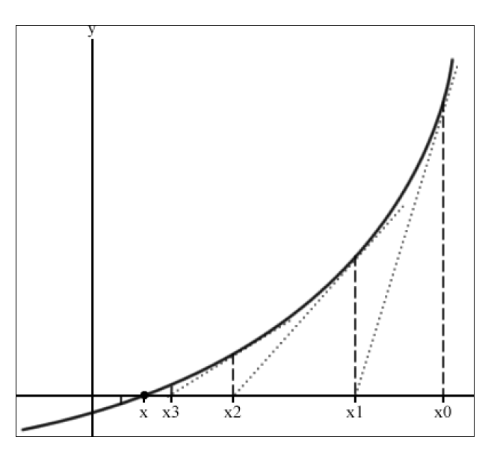

In [2]:
Image.open(os.path.join(path_dir,'IV_1.png'))

In [3]:
import bsm
reload(bsm)

<module 'bsm' from 'C:\\Old SSD Data\\C Drive\\Desktop\\CQF Course\\Python Labs\\Implied Volatility\\bsm.py'>

In [4]:
def newton_ralphson(spot,strike,rate,days_to_maturity,callprice=None,putprice=None):
    
    x0 = 1                 # initial guess
    h = 0.001              # step size in calculation os f'(x)
    tolerance = 1e-7       # 7-digit accuracy is desired
    epsilon = 1e-14        # do not divide by a number smaller than this, some kind of error / floor
    max_iter = 200
    
    # function whose root we are trying to find
    # f(x) = Black Scholes Call price - Market Price - defining the f(x) here
    
    if callprice:
        f = lambda x: bsm.BlackScholes(spot,strike,rate,days_to_maturity,x).call_price - callprice
    if putprice and not callprice:
        f = lambda x: bsm.BlackScholes(spot,strike,rate,days_to_maturity,x).put_price - putprice
        
    for i in range(max_iter):
        y= f(x0)                                   # starting with initial guess
        y_prime = (f(x0+h) -f(x0-h))/(2*h)         # central difference, the derivative of the function
        
        # we check 2 conditions :
        # first absolute difference between x1 and x0 
        # absolute of y_prime should not be less than eplision - stop if the denominator is too small
        
        if abs(y_prime) < epsilon:                  # stop if the denominator is too small
            break
        else:
            pass
        
        x1 = x0 - (y/y_prime)                       # perform Newton's computation
        
        if (abs(x1-x0) <= tolerance*abs(x1)):
            break                                   # stop when the result is within the desired tolerance
        else:
            pass
        
        x0 = x1                                     # update x0 to start the process again
        
        return x1                                   # x1 is a solution within tolerance and maximum number of iterations
          

In [5]:
newton_ralphson(100,100,0.02,1,callprice=8)

0.11302514612176828

## Bisection Method

The bisection method is considered to be one of the simplest and robust root finding algorithm.

Suppose, we know the two points of an interval a and b, where a < b and f(a) < 0 and f(b) > 0 lie along the continuous function and the mid-point of this interval c = (a+b)/2, then we can evaluate the value as 
f(c).

Iteratively, we replace c as either aor b, thereby shortening the interval to find the root. If 
f(c) =0 or within acceptable value, we have a root. Bisection methods are stable and guarantee to converge. As it does not require knowledge of the derivative, it takes more computational time.

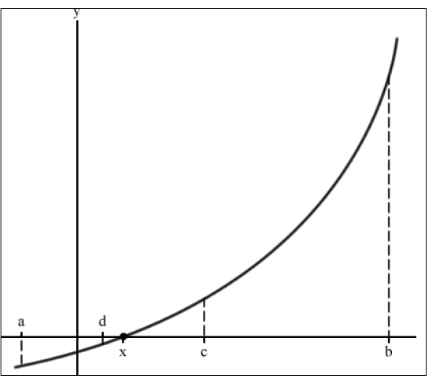

In [6]:
Image.open(os.path.join(path_dir,'IV_2.png'))

In [7]:
def bisection(spot,strike,rate,days_to_maturity,high =500, low= 0,callprice=None,putprice=None):
    
    tolerance = 1e-7
    max_iter = 200
    
    if callprice:
        price = callprice
    if putprice and not callprice:
        pice = putprice
        
    for i in range(max_iter):
        mid = (high + low) / 2
        
        # we check condition : implied volatility can't go negative
        
        if mid < tolerance:
            mid = tolerance
        
        if callprice:
            estimate = bsm.BlackScholes(spot,strike,rate,days_to_maturity,mid).call_price
        if putprice:
            estimate = bsm.BlackScholes(spot,strike,rate,days_to_maturity,mid).put_price
            
        if round(estimate,6)== price:
            break
        elif estimate > price:
            high = mid
        elif estimate < price:
            low = mid
    
    return mid
            

In [8]:
bisection(100,100,0.02,1,callprice=8.)

0.17657213902566582

## BS Implied Volatility

Let's now update our Blackscholes' class to incorporate implied volatility.

In [32]:
import vol
reload(vol)

<module 'vol' from 'C:\\Old SSD Data\\C Drive\\Desktop\\CQF Course\\Python Labs\\Implied Volatility\\vol.py'>

In [35]:
option = vol.BlackScholes(100,100,0.05,1,0.2, callprice=8)

header = ['Option Price', 'Delta', 'Gamma', 'Theta', 'Vega', 'Rho', 'IV']
table = [[option.call_price, option.call_delta, option.gamma, option.call_theta, option.vega, option.call_rho, option.imp_vol]]

print(tabulate(table,header))

  Option Price     Delta     Gamma     Theta    Vega      Rho        IV
--------------  --------  --------  --------  ------  -------  --------
       10.4506  0.636831  0.018762  -6.41403  37.524  53.2325  0.133776


## References

[Python Resources](https://github.com/kannansingaravelu/PythonResources)